In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

utvalg = pd.read_csv("utvalg.csv")
utvalg["klasse"].value_counts()

klasse
NORM         100
LVH          100
LAFB/LPFB    100
ISCA         100
ISCI         100
IRBBB        100
STTC         100
CLBBB        100
IMI          100
AMI          100
NST_         100
CRBBB         98
IVCD          94
Name: count, dtype: int64

In [15]:
emb = np.load("data/embeddings.npy")
rekke = pd.read_csv("data/embeddings_rekkefolge.csv")

print(emb.shape)
print((rekke["ecg_id"].values == utvalg["ecg_id"].values).all())

klasser = rekke["klasse"].to_numpy(dtype=str)

(1292, 1024)
True


In [16]:
# PCA

from sklearn.decomposition import PCA

pca = PCA(n_components=50, random_state=305)
emb_pca = pca.fit_transform(emb)

print(emb_pca.shape)
print(pca.explained_variance_ratio_[:2].sum())

(1292, 50)
0.15633172


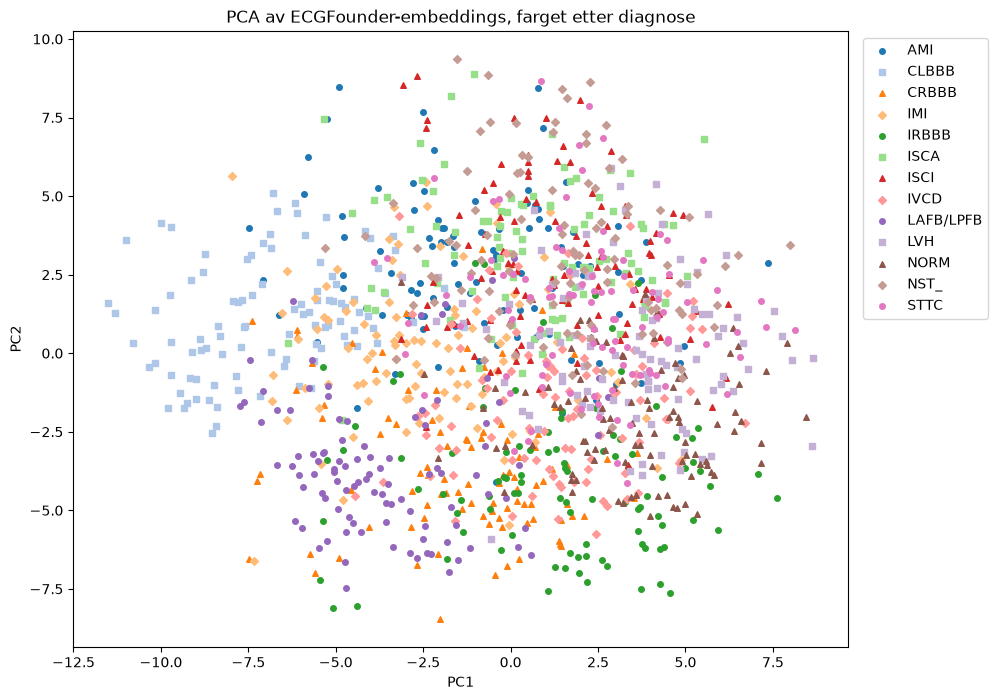

In [17]:
klassenavn = sorted(set(klasser))
farger = plt.cm.tab20.colors
former = ["o", "s", "^", "D"]

plt.figure(figsize=(10, 8))
for i, k in enumerate(klassenavn):
    m = klasser == k
    plt.scatter(emb_pca[m, 0], emb_pca[m, 1], s=16,
                color=farger[i], marker=former[i % 4], label=k)

plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.title("PCA av ECGFounder-embeddings, farget etter diagnose")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

In [18]:
def plott(xy, tittel):
    plt.figure(figsize=(10, 8))
    for i, k in enumerate(klassenavn):
        m = klasser == k
        plt.scatter(xy[m, 0], xy[m, 1], s=16,
                    color=farger[i], marker=former[i % 4], label=k)
    plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
    plt.title(tittel)
    plt.show()

/home/fishy/projects/DAT305/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


(1292, 2)


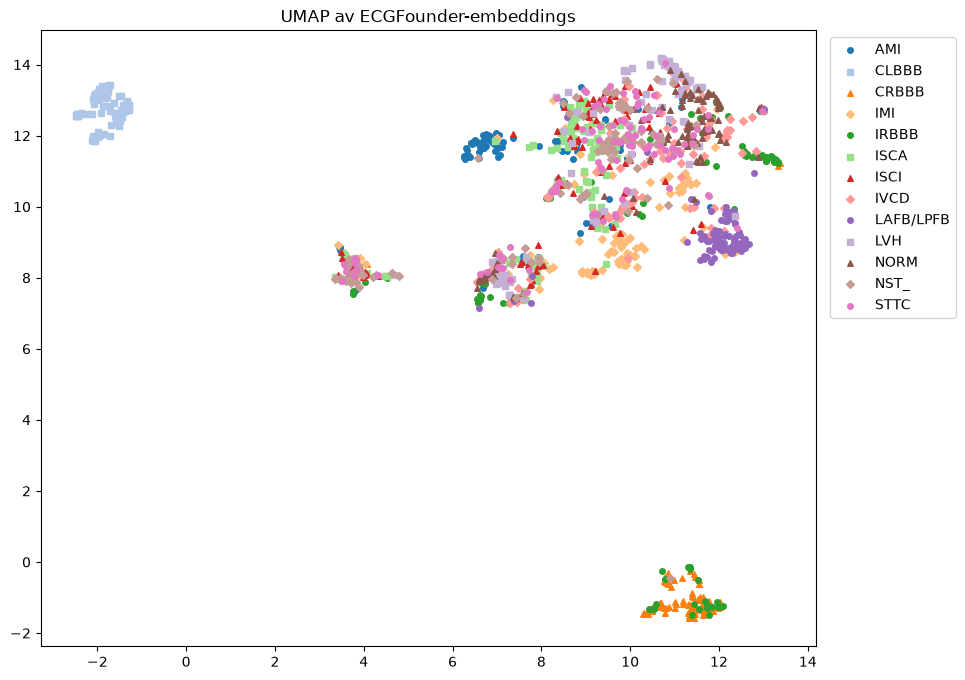

In [19]:
import umap

reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=305)
emb_umap = reducer.fit_transform(emb_pca)

print(emb_umap.shape)
plott(emb_umap, "UMAP av ECGFounder-embeddings")

In [20]:
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

def knn_enighet(X, etiketter, k=10, metric="euclidean"):
    nn = NearestNeighbors(n_neighbors=k + 1, metric=metric).fit(X)
    _, idx = nn.kneighbors(X)
    naboer = idx[:, 1:]
    return (etiketter[naboer] == etiketter[:, None]).mean()

rom = {
    "1024-D (cosinus)": (emb, "cosine"),
    "PCA-2": (emb_pca[:, :2], "euclidean"),
    "UMAP-2": (emb_umap, "euclidean"),
}

stokket = np.random.default_rng(305).permutation(klasser)

for navn, (X, metric) in rom.items():
    knn = knn_enighet(X, klasser, metric=metric)
    tilf = knn_enighet(X, stokket, metric=metric)
    sil = silhouette_score(X, klasser, metric=metric)
    print(f"{navn:18}  k-NN {knn:.2f}  (tilfeldig {tilf:.2f})  silhouette {sil:.2f}")

1024-D (cosinus)    k-NN 0.50  (tilfeldig 0.08)  silhouette 0.05
PCA-2               k-NN 0.25  (tilfeldig 0.08)  silhouette -0.08
UMAP-2              k-NN 0.46  (tilfeldig 0.08)  silhouette 0.06


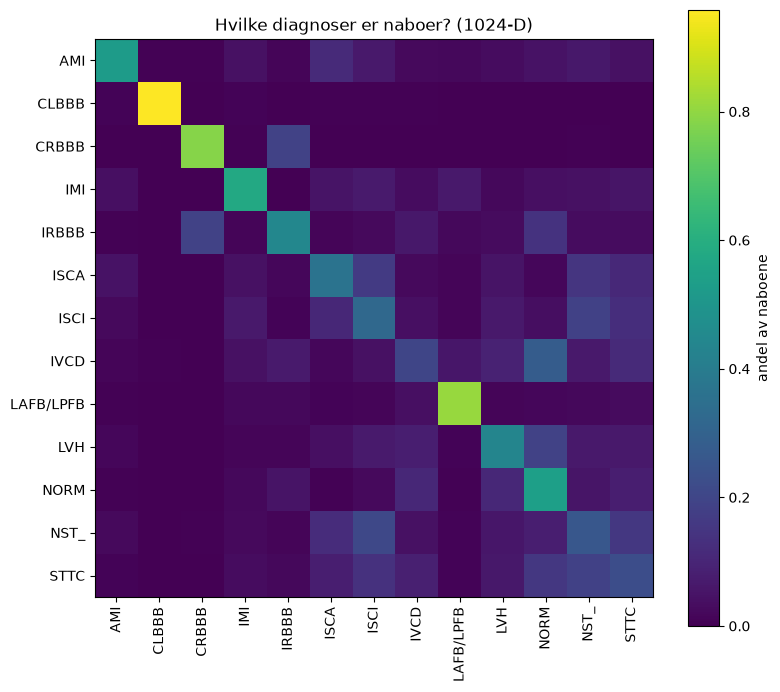

IVCD         0.201064
STTC         0.225000
NST_         0.259000
ISCI         0.325000
ISCA         0.365000
LVH          0.435000
IRBBB        0.444000
AMI          0.524000
NORM         0.542000
IMI          0.580000
CRBBB        0.784694
LAFB/LPFB    0.811000
CLBBB        0.958000
dtype: float64


In [21]:
def naboblanding(X, metric, k=10):
    X = np.ascontiguousarray(X, dtype=np.float64)
    nn = NearestNeighbors(n_neighbors=k + 1, metric=metric, algorithm="brute").fit(X)
    _, idx = nn.kneighbors(X)
    naboer = klasser[idx[:, 1:]]
    M = pd.DataFrame(0.0, index=klassenavn, columns=klassenavn)
    for a in klassenavn:
        rader = naboer[klasser == a]
        for b in klassenavn:
            M.loc[a, b] = (rader == b).mean()
    return M

M = naboblanding(emb, "cosine")

plt.figure(figsize=(9, 8))
plt.imshow(M, cmap="viridis")
plt.colorbar(label="andel av naboene")
plt.xticks(range(13), klassenavn, rotation=90)
plt.yticks(range(13), klassenavn)
plt.title("Hvilke diagnoser er naboer? (1024-D)")
plt.show()

print(pd.Series(np.diag(M), index=klassenavn).sort_values())

In [23]:
tall = M.to_numpy().copy()
np.fill_diagonal(tall, 0)
par = pd.DataFrame(tall, index=M.index, columns=M.columns)

topp = par.stack().sort_values(ascending=False).head(8)
for (a, b), v in topp.items():
    print(f"{a:10} har {v:.0%} naboer som er {b}")

IVCD       har 28% naboer som er NORM
NST_       har 21% naboer som er ISCI
LVH        har 19% naboer som er NORM
CRBBB      har 19% naboer som er IRBBB
IRBBB      har 19% naboer som er CRBBB
ISCI       har 19% naboer som er NST_
STTC       har 18% naboer som er NST_
ISCA       har 16% naboer som er ISCI
